# AI Expense Tool — Colab edition

Receipt photo ➜ **OCR** ➜ **Extract** (merchant, date, totals, tax, currency) ➜ **Validate** (arithmetic) ➜ **Classify** (rules + BERT embeddings) ➜ **Policy analysis** (LLM reads the company expense policy and decides) ➜ review / export.

Ported from [SubodhAmbade/ai-expense-tool](https://github.com/SubodhAmbade/ai-expense-tool) with the same core principle:
**a deterministic engine handles the numbers; AI only makes suggestions.** Nothing is finalised without a confidence check or a human confirming it.

| Stage | Method | Notes |
|---|---|---|
| 1. OCR | RapidOCR (ONNX, CPU) | boxes grouped into rows so `TOTAL ... 12.50` becomes one line |
| 2. Extract | regex rules, no AI | every field carries a confidence = rule strength × OCR confidence |
| 3. Validate | plain code | `subtotal + tax = total` or `cash − change = total`, tax rate plausible, date sane |
| 4. Classify | merchant/item rules, then BERT (`bge-small-en-v1.5`) | zero-shot vs category descriptions **and** k-NN vs labelled merchants |
| 5. Policy | Qwen 2.5 Instruct, running locally in Colab | Qwen judges the claim in plain `KEY: value` lines; code parses them and applies the decision rule |

**How to run:** `Runtime ▸ Change runtime type ▸ T4 GPU`, then `Runtime ▸ Run all`. Nothing blocks: sections 0–8 run on built-in sample receipts, and **section 9 at the end** is where you upload your own photos. Everything runs inside Colab, with no API keys and no external LLM calls. Qwen's weights download once from Hugging Face (about 6 GB for the 3B model on GPU, 3 GB for the 1.5B model on CPU). If Qwen can't load, the policy stage falls back to a rule-based check.


## 0 · Setup

In [ ]:
%%capture
!pip install -q "rapidocr>=3.0" onnxruntime fastembed pillow numpy "pydantic>=2" pyyaml pandas ipywidgets
# local LLM (Qwen) - already in Colab, this makes sure the versions are recent enough
!pip install -q "transformers>=4.56" accelerate

In [2]:
import csv, io, json, os, re, time, textwrap
from datetime import date
from decimal import Decimal
from functools import lru_cache
from io import BytesIO, StringIO
from pathlib import Path
from typing import BinaryIO, Generic, Literal, TypeVar

import numpy as np
import pandas as pd
import yaml
from PIL import Image, ImageDraw, ImageFont, ImageOps
from pydantic import BaseModel, field_validator

try:
    from google.colab import files as colab_files  # type: ignore
    IN_COLAB = True
except Exception:
    IN_COLAB = False

WORK = Path("receipts"); WORK.mkdir(exist_ok=True)
print("Colab:", IN_COLAB)

Colab: True


### Tax profiles (data, not code)
Rates per region. Add a region by adding a YAML entry.

In [3]:
TAX_PROFILES_YAML = """
# Tax rates per region, as fractions. Write them as quoted strings so they load as exact decimals.
# Add a region by adding a profile; no code changes needed.
profiles:
  generic:
    name: Generic (single standard rate, edit for your region)
    default_currency: USD
    date_order: unknown  # read day-first, but send dates like 03/04 to review
    rates:
      standard: "0.10"
      zero: "0"

  ch:
    name: Switzerland (MWST/TVA/IVA, rates from 1 Jan 2024)
    default_currency: CHF
    date_order: dmy
    rates:
      standard: "0.081"
      accommodation: "0.038"
      reduced: "0.026"
      zero: "0"

  my:
    name: Malaysia (GST 6% Apr 2015 - May 2018; SST from Sep 2018)
    default_currency: MYR
    date_order: dmy
    rates:
      gst: "0.06"
      sales_tax: "0.10"
      sales_tax_reduced: "0.05"
      service_tax: "0.08"  # 6% until Mar 2024, still 6% for F&B, telecoms, logistics
      service_tax_reduced: "0.06"
      zero: "0"
"""


class TaxProfile(BaseModel):
    code: str
    name: str
    default_currency: str
    date_order: Literal["dmy", "mdy", "unknown"] = "unknown"  # how to read 03/04/2025
    rates: dict[str, Decimal]

    @field_validator("rates")
    @classmethod
    def rates_in_range(cls, v):
        if not v:
            raise ValueError("a profile needs at least one rate")
        for name, rate in v.items():
            if not Decimal("0") <= rate < Decimal("1"):
                raise ValueError(f"rate '{name}' must be a fraction, got {rate}")
        return v


def load_tax_profiles(text: str) -> dict[str, TaxProfile]:
    raw = yaml.safe_load(text)
    return {
        code: TaxProfile(code=code, **{**p, "rates": {k: str(r) for k, r in p["rates"].items()}})
        for code, p in raw["profiles"].items()
    }


PROFILES = load_tax_profiles(TAX_PROFILES_YAML)
PROFILE = PROFILES["my"]  # <- change to "generic", "ch", "my" or add your own above
print({k: v.name for k, v in PROFILES.items()})

{'generic': 'Generic (single standard rate, edit for your region)', 'ch': 'Switzerland (MWST/TVA/IVA, rates from 1 Jan 2024)', 'my': 'Malaysia (GST 6% Apr 2015 - May 2018; SST from Sep 2018)'}


## 1 · OCR — receipt image ➜ text rows

RapidOCR returns one box per word-group. Receipts print the label and the amount as separate boxes (`TOTAL` … `12.50`), so boxes are grouped into **rows** by vertical centre; that is what makes the text usable by the extractor.

In [4]:
from rapidocr import RapidOCR

MAX_SIDE = 2000  # px; bigger photos are shrunk, small print is still readable
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".webp"}
ENGINE_SETTINGS = {
    "Det.limit_type": "max",
    "Det.limit_side_len": 960,
    "Global.use_cls": False,   # receipts are photographed upright
    "Rec.rec_batch_num": 2,
}


class OcrLine(BaseModel):
    text: str
    confidence: float
    box: list[list[int]]  # 4 corners clockwise from top-left
    row: int


class OcrResult(BaseModel):
    engine: str = "rapidocr"
    duration_ms: int
    lines: list[OcrLine]
    text: str  # rows joined by newlines, boxes on a row joined by spaces


@lru_cache
def _engine() -> RapidOCR:
    return RapidOCR(params=ENGINE_SETTINGS)


def load_image(source) -> Image.Image:
    image = Image.open(source)
    image.draft("RGB", (MAX_SIDE, MAX_SIDE))
    if image.mode in ("1", "P"):
        image = image.convert("L" if image.mode == "1" else "RGBA" if "transparency" in image.info else "RGB")
    image.thumbnail((MAX_SIDE, MAX_SIDE))
    image = ImageOps.exif_transpose(image)
    if "A" in image.getbands():  # transparent areas would turn black
        image = Image.alpha_composite(Image.new("RGBA", image.size, "white"), image.convert("RGBA"))
    return image.convert("RGB")


def run_ocr(source: str | Path | BinaryIO) -> OcrResult:
    start = time.perf_counter()
    image = load_image(source)
    out = _engine()(np.asarray(image))
    lines = (
        [OcrLine(text=t, confidence=round(float(s), 3), box=np.asarray(b).astype(int).tolist(), row=-1)
         for b, t, s in zip(out.boxes, out.txts, out.scores, strict=True)]
        if out.boxes is not None else []
    )
    # group boxes into rows: join the current row if the vertical centre lies within half a line height
    rows: list[list[OcrLine]] = []
    for line in sorted(lines, key=lambda ln: ln.box[0][1] + ln.box[2][1]):
        centre = (line.box[0][1] + line.box[2][1]) / 2
        if rows:
            first = rows[-1][0]
            first_centre = (first.box[0][1] + first.box[2][1]) / 2
            if abs(centre - first_centre) < (first.box[2][1] - first.box[0][1]) / 2:
                rows[-1].append(line)
                continue
        rows.append([line])
    rows = [sorted(row, key=lambda ln: ln.box[0][0]) for row in rows]
    for i, row in enumerate(rows):
        for ln in row:
            ln.row = i
    return OcrResult(
        duration_ms=round((time.perf_counter() - start) * 1000),
        lines=[ln for row in rows for ln in row],
        text="\n".join(" ".join(ln.text for ln in row) for row in rows),
    )


print("OCR engine ready")

OCR engine ready


### Sample receipts
The notebook ships with three synthetic receipts (a working meal with beer, a stationery purchase, a hotel folio with mini bar) so every stage runs unattended. **Your own photos go in at the end** (section 9), once all the functions are defined.

rendered: ['sample_meal.png', 'sample_stationery.png', 'sample_hotel.png']


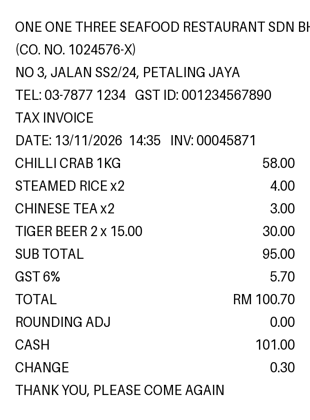

In [5]:
# Render synthetic receipts so the pipeline can run end-to-end without any files
def render_receipt(lines: list[str], path: Path, width=620, size=26) -> Path:
    try:
        font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSansMono.ttf", size)
    except OSError:
        font = ImageFont.load_default(size=size)
    pad, lh = 30, int(size * 1.55)
    img = Image.new("RGB", (width, pad * 2 + lh * len(lines)), "white")
    d = ImageDraw.Draw(img)
    for i, line in enumerate(lines):
        if "\t" in line:  # label left, amount right
            label, amount = line.split("\t")
            d.text((pad, pad + i * lh), label, fill="black", font=font)
            w = d.textlength(amount, font=font)
            d.text((width - pad - w, pad + i * lh), amount, fill="black", font=font)
        else:
            d.text((pad, pad + i * lh), line, fill="black", font=font)
    img.save(path)
    return path

from datetime import timedelta
_d = lambda days_ago, fmt="%d/%m/%Y": (date.today() - timedelta(days=days_ago)).strftime(fmt)

SAMPLES = {
    "sample_meal.png": [
        "ONE ONE THREE SEAFOOD RESTAURANT SDN BHD",
        "(CO. NO. 1024576-X)",
        "NO 3, JALAN SS2/24, PETALING JAYA",
        "TEL: 03-7877 1234   GST ID: 001234567890",
        "TAX INVOICE",
        f"DATE: {_d(4)}  14:35   INV: 00045871",
        "CHILLI CRAB 1KG\t58.00",
        "STEAMED RICE x2\t4.00",
        "CHINESE TEA x2\t3.00",
        "TIGER BEER 2 x 15.00\t30.00",
        "SUB TOTAL\t95.00",
        "GST 6%\t5.70",
        "TOTAL\tRM 100.70",
        "ROUNDING ADJ\t0.00",
        "CASH\t101.00",
        "CHANGE\t0.30",
        "THANK YOU, PLEASE COME AGAIN",
    ],
    "sample_stationery.png": [
        "SANYU STATIONERY SHOP",
        "NO. 31G&33G, JALAN SETIA INDAH X",
        "TEL: 012-918 7937",
        "CASH RECEIPT",
        f"DATE: {_d(9, '%d-%b-%Y').upper()} 11:02",
        "A4 PAPER 80GSM 500S\t12.90",
        "BALLPOINT PEN BLUE x10\t8.50",
        "STAPLER NO.10\t6.40",
        "TOTAL AMOUNT\t27.80",
        "VISA\t27.80",
        "GST SUMMARY   AMT   TAX",
        "SR @ 6%   26.23   1.57",
    ],
    "sample_hotel.png": [
        "GRAND MILLENNIUM HOTEL KUALA LUMPUR",
        "160 JALAN BUKIT BINTANG",
        "FOLIO 884512  ROOM 1807",
        f"DATE {_d(75)}",
        "ROOM CHARGE 1 NIGHT\t520.00",
        "MINI BAR\t45.00",
        "IN-ROOM MOVIE\t28.00",
        "SUB TOTAL\t593.00",
        "SERVICE CHARGE 10%\t59.30",
        "GST 6%\t39.14",
        "GRAND TOTAL\tRM 691.44",
        "MASTERCARD\t691.44",
    ],
}
for name, lines in SAMPLES.items():
    render_receipt(lines, WORK / name)
print("rendered:", list(SAMPLES))
display(Image.open(WORK / "sample_meal.png").resize((310, 420)))

In [6]:
receipt_paths = sorted(p for p in WORK.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)
ocr_results = {p.name: run_ocr(p) for p in receipt_paths}
for name, r in ocr_results.items():
    mean = sum(l.confidence for l in r.lines) / max(len(r.lines), 1)
    print(f"=== {name}: {len(r.lines)} boxes, mean conf {mean:.2f}, {r.duration_ms} ms")
    print(r.text, "\n")

[INFO] 2026-11-17 01:33:24,089 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-11-17 01:33:24,179 [RapidOCR] download_file.py:60: File exists and is valid: /usr/local/lib/python3.13/dist-packages/rapidocr/models/PP-OCRv6_det_small.onnx
[INFO] 2026-11-17 01:33:24,181 [RapidOCR] main.py:63: Using /usr/local/lib/python3.13/dist-packages/rapidocr/models/PP-OCRv6_det_small.onnx
[INFO] 2026-11-17 01:33:24,843 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-11-17 01:33:24,906 [RapidOCR] download_file.py:60: File exists and is valid: /usr/local/lib/python3.13/dist-packages/rapidocr/models/PP-OCRv6_rec_small.onnx
[INFO] 2026-11-17 01:33:24,907 [RapidOCR] main.py:63: Using /usr/local/lib/python3.13/dist-packages/rapidocr/models/PP-OCRv6_rec_small.onnx


=== sample_hotel.png: 20 boxes, mean conf 0.99, 1678 ms
GRAND MILLENNIUM HOTEL KUALA LUMPUR
160 JALAN BUKIT BINTANG
FOLIO 884512 ROOM 1807
DATE 03/09/2026
ROOM CHARGE 1 NIGHT 520.00
MINI BAR 45.00
IN-ROOM MOVIE 28.00
SUB TOTAL 593.00
SERVICE CHARGE 10% 59.30
GST 6% 39.14
GRAND TOTAL RM 691.44
MASTERCARD 691.44 

=== sample_meal.png: 27 boxes, mean conf 0.99, 1800 ms
ONE ONE THREE SEAFOOD RESTAURANT SDN BH
(CO. NO. 1024576-X)
NO 3, JALAN SS2/24, PETALING JAYA
TEL: 03-7877 1234 GST ID: 001234567890
TAX INVOICE
DATE: 13/11/202614:35 INV: 00045871
CHILLI CRAB 1KG 58.00
STEAMED RICE x2 4.00
CHINESE TEA x2 3.00
TIGER BEER 2 x 15.00 30.00
SUB TOTAL 95.00
GST 6% 5.70
TOTAL RM 100.70
ROUNDING ADJ 0.00
CASH 101.00
CHANGE 0.30
THANK YOU, PLEASE COME AGAIN 

=== sample_stationery.png: 19 boxes, mean conf 0.99, 1513 ms
SANYU STATIONERY SHOP
NO. 31G&33G, JALAN SETIA INDAH X
TEL: 012-918 7937
CASH RECEIPT
DATE: 08-NOV-2026 11:02
A4 PAPER 80GSM 500S 12.90
BALLPOINT PEN BLUE x10 8.50
STAPLER NO.10 6.40

## 2 · Extract — rows ➜ merchant, date, total, subtotal, tax, cash, change, currency

Deterministic rules only. Each field = `Field(value, confidence, source_row)`; confidence is *rule strength × OCR confidence of the row*, so low-confidence values can be routed to review and highlighted in a UI.

In [ ]:
from difflib import get_close_matches

T = TypeVar("T")

CURRENCY_PREFIX = re.compile(r"^(RM|MYR|CHF|EUR|USD|\$|€|£)?\s*")
AMOUNT = re.compile(r"(?<![\d.,])\d{1,3}(?:,\d{3})*\.\d{2}(?![\d%])|(?<![\d.,])\d+\.\d{2}(?![\d%])")

TOTAL_RULES = [  # (pattern, rule confidence); first rule with a match wins
    (re.compile(r"ROUND\w*\s*\w?\s*TOTAL|TOTAL\s*(AMT\s*|AMOUNT\s*)?ROUND|AFTER\s*(ROUND\w*\s*)?(ADJ|ROUND)"), 1.0),
    (re.compile(r"N\s*ETT?\s*TOTAL|GRAND\s*TOTAL|TOTAL\s*(AMOUNT|AMT|PAYABLE|SALES|INCL|DUE)|(AMT|AMOUNT|BALANCE)\s*DUE|NETT?\s*AMT"), 0.95),
    (re.compile(r"\b(TOTAL|TOTL|TTL)\b"), 0.9),
]
CASH_RULES = [(re.compile(r"\b(CASH|VISA|MASTER\w*|CARD|PAID|PAYMENT|TENDER\w*)\b"), 0.6)]
CHANGE_RULES = [(re.compile(r"\bCHANGE\b"), 0.9)]
NOT_TOTAL = re.compile(
    r"SUB\s*-?\s*TOTA|EXCL|TOTAL\s*Q|QTY|ITEM|DISC|SAV|CHANGE|(?<!AFTER )(?<!ROUNDING )ADJ|"
    r"TOTAL\s*(GST|TAX|SST|VAT)|(GST|TAX|SST|VAT)\s*TOTAL|INCLUDED\s*(GST|TAX)\s*@"
)
TAX_SUMMARY = re.compile(r"(GST|TAX|SST)\s*SUMMARY|SUMMARY\s*(OF\s*)?(GST|TAX)")
KEYWORDS = ("TOTAL", "PAYABLE")  # read through one-letter OCR slips: TATAL, TOTAI
WORD = re.compile(r"\b[A-Z]{4,7}\b")
ROUNDING_MAX = Decimal("0.10")
ROUNDING = re.compile(r"ROUND\w*\s*(ADJ|\(|:|-?\.?\d|RM)")
SIGNED_AMOUNT = re.compile(r"(-?)\s*(\d*\.\d{2})\s*$")
SUBTOTAL_RULES = [(re.compile(r"SUB\s*-?\s*TOTA|TOTAL\s*EXCL|AMOUNT\s*EXCL"), 0.85)]
SERVICE_RULES = [(re.compile(r"SERVICE\s*(CHARGE|CHG)|SERV\.?\s*(CHARGE|CHG)|SVC\s*(CHARGE|CHG)"), 0.85)]
TAX_RULES = [
    (re.compile(r"TOTAL\s*(GST|TAX|VAT|SST)|(GST|TAX|VAT|SST)\s*(AMOUNT|AMT|TOTAL)"), 0.85),
    (re.compile(r"\b(GST|TAX|VAT|SST|MWST|TVA|IVA)\b"), 0.75),
]
NOT_TAX = re.compile(
    r"INCL|EXCL|\bINC\b|WITH|SUB|TAXABLE|\bID\b|REG|NO\b|INVOICE|"
    r"(?<!GST )(?<!TAX )(?<!VAT )(?<!SST )TOTAL(?!\s*(GST|TAX|VAT|SST))"
)
DATE_PATTERNS = [
    (re.compile(r"\b(\d{4})[/.-](\d{1,2})[/.-](\d{1,2})\b"), "ymd"),
    (re.compile(r"\b(\d{1,2})[/.-](\d{1,2})[/.-](\d{4}(?=\d{1,2}:)|(?:\d{4}|\d{2})(?!\d))"), "a"),
    (re.compile(r"\b(\d{1,2})\s*-?(JAN|FEB|MAR|APR|MAY|JUN|JUL|AUG|SEP|OCT|NOV|DEC)\w*\s*-?(\d{4}|\d{2})\b"), "dmy"),
]
MONTHS = "JAN FEB MAR APR MAY JUN JUL AUG SEP OCT NOV DEC".split()
CURRENCIES = {
    "RM": "MYR", "MYR": "MYR", "CHF": "CHF", "SFR": "CHF", "FR.": "CHF", "EUR": "EUR", "€": "EUR",
    "GBP": "GBP", "£": "GBP", "USD": "USD", "US$": "USD", "AUD": "AUD", "A$": "AUD",
    "SGD": "SGD", "S$": "SGD", "NZD": "NZD", "INR": "INR", "₹": "INR",
}
CURRENCY = re.compile(r"(?<![A-Z])(" + "|".join(re.escape(k) for k in CURRENCIES) + r")(?![A-Z])")
JUNK_MERCHANT = re.compile(
    r"\bTEL\b|FAX|PHONE|GST|REG|CO\.?\s*NO|INVOICE|RECEIPT|FORMERLY|LICENSEE|^\W*$|"  # \bTEL\b: keep HOTEL names
    r"JALAN|JLN|TAMAN|STREET|ROAD|AVENUE|FLOOR|FLR|LEVEL|LOT\b|^NO[.: ]|\d+,"
)
COMPANY_SUFFIX = re.compile(r"\b(SDN\.?\s*BHD|S/B|BHD|LTD|LLC|INC|GMBH|AG|PTY|ENTERPRISE|TRADING|RESTAURANTS?)\b\.?|\bCO\.")
REG_LINE = re.compile(r"(CO|COMPANY|GST|ROC)\.?\s*(NO|REG|ID)")
REG_NUMBER = re.compile(r"\(?[\w-]*\d{4,}[\w-]*\)?")


class Field(BaseModel, Generic[T]):
    value: T | None = None
    confidence: float = 0.0
    source_row: int | None = None


class ExtractResult(BaseModel):
    merchant: Field[str]
    date: Field[date]
    total: Field[Decimal]
    subtotal: Field[Decimal]
    tax: Field[Decimal]
    service: Field[Decimal] = Field()  # service charge (hotels, restaurants), 0 if absent
    cash: Field[Decimal]
    change: Field[Decimal]
    currency: Field[str]


def _find_amount(rows, conf, rules, exclude=None, positive=False) -> Field[Decimal]:
    for pattern, weight in rules:
        hits = []
        for i, row in enumerate(rows):
            if not pattern.search(row) or (exclude and exclude.search(row)):
                continue
            amounts = AMOUNT.findall(row)
            next_row = CURRENCY_PREFIX.sub("", rows[i + 1].strip()) if i + 1 < len(rows) else ""
            if not amounts and AMOUNT.fullmatch(next_row):
                amounts, i = [next_row], i + 1
            if amounts:
                value = Decimal(amounts[-1].replace(",", ""))
                if value > 0 or not positive:
                    hits.append((value, i))
        if hits:
            value, i = max(hits)
            return Field(value=value, confidence=round(weight * conf[i], 3), source_row=i)
    return Field()


def _total(rows, conf, cash, change) -> Field[Decimal]:
    end = next((i for i, row in enumerate(rows) if TAX_SUMMARY.search(row)), len(rows))
    total = _find_amount(rows[:end], conf, TOTAL_RULES, NOT_TOTAL, positive=True)
    if total.value is None and cash.value is not None:
        paid = cash.value - (change.value or 0)
        return Field(value=paid, confidence=cash.confidence, source_row=cash.source_row)
    if total.value is not None and not TOTAL_RULES[0][0].search(rows[total.source_row]):
        for row in rows[total.source_row + 1 : end]:
            if ROUNDING.search(row) and (m := SIGNED_AMOUNT.search(row)):
                amount = Decimal(m.group(1) + m.group(2))
                if abs(amount) < ROUNDING_MAX:
                    total.value += amount
                elif abs(amount - total.value) < ROUNDING_MAX:
                    total.value = amount
                break
    return total


def _merchant(raw, conf) -> Field[str]:
    candidates = []
    for i, row in enumerate(raw[:8]):
        if REG_LINE.search(row.upper()):
            continue
        name = REG_NUMBER.sub("", row).strip(" -,")
        label, _, rest = name.partition(":")
        if rest and not COMPANY_SUFFIX.search(label.upper()):
            name = rest.strip()
        if (name.count("(") > name.count(")") or name.endswith("&")) and i + 1 < len(raw):
            name = f"{name} {REG_NUMBER.sub('', raw[i + 1]).strip()}"
        suffixes = list(COMPANY_SUFFIX.finditer(name.upper()))
        if suffixes and i > 0 and sum(c.isalpha() for c in COMPANY_SUFFIX.sub("", name.upper())) < 3:
            name = f"{raw[i - 1].strip()} {name}"
            suffixes = list(COMPANY_SUFFIX.finditer(name.upper()))
        if suffixes:
            candidates.append((0.95, i, name[: suffixes[-1].end()].strip()))
        elif sum(c.isalpha() for c in name) >= 4 and not name.islower() and not JUNK_MERCHANT.search(name.upper()):
            candidates.append((0.85 if not candidates and i == 0 else 0.7, i, name))
    if not candidates:
        return Field()
    weight, i, name = max(candidates, key=lambda c: (c[0], -c[1]))
    return Field(value=name, confidence=round(weight * conf[i], 3), source_row=i)


def _date(rows, conf, profile: TaxProfile) -> Field[date]:
    for i in sorted(range(len(rows)), key=lambda i: "DATE" not in rows[i]):
        for pattern, order in DATE_PATTERNS:
            pos = 0
            while m := pattern.search(rows[i], pos):
                pos = m.start() + 1
                a, b, c = m.groups()
                if order == "ymd":
                    y, mo, d = int(a), int(b), int(c)
                elif order == "dmy":
                    d, mo, y = int(a), MONTHS.index(b) + 1, int(c)
                else:
                    d, mo = (int(b), int(a)) if profile.date_order == "mdy" else (int(a), int(b))
                    y = int(c)
                try:
                    value = date(y + 2000 if y < 100 else y, mo, d)
                except ValueError:
                    continue
                ambiguous = order == "a" and int(a) <= 12 and int(b) <= 12 and a != b and profile.date_order == "unknown"
                return Field(value=value, confidence=round((0.7 if ambiguous else 0.95) * conf[i], 3), source_row=i)
    return Field()


def _keyword(m: re.Match) -> str:
    return (get_close_matches(m.group(), KEYWORDS, n=1, cutoff=0.8) or [m.group()])[0]


def extract(ocr: OcrResult, profile: TaxProfile) -> ExtractResult:
    raw = [" ".join(r.split()) for r in ocr.text.splitlines()]
    rows = [WORD.sub(_keyword, r.upper()) for r in raw]
    conf = [min((ln.confidence for ln in ocr.lines if ln.row == i), default=0.0) for i in range(len(rows))]
    currency = Field(value=profile.default_currency, confidence=0.5 if profile.code == "generic" else 0.85)
    for i, row in enumerate(rows):
        if m := CURRENCY.search(row):
            currency = Field(value=CURRENCIES[m.group(1)], confidence=0.95, source_row=i)
            break
    cash = _find_amount(rows, conf, CASH_RULES, re.compile(r"CHANGE"))
    change = _find_amount(rows, conf, CHANGE_RULES)
    return ExtractResult(
        merchant=_merchant(raw, conf),
        date=_date(rows, conf, profile),
        total=_total(rows, conf, cash, change),
        subtotal=_find_amount(rows, conf, SUBTOTAL_RULES),
        tax=_find_amount(rows, conf, TAX_RULES, NOT_TAX),
        service=_find_amount(rows, conf, SERVICE_RULES),
        cash=cash,
        change=change,
        currency=currency,
    )


def show_fields(fields: ExtractResult) -> pd.DataFrame:
    return pd.DataFrame(
        [{"field": k, "value": v.value, "confidence": v.confidence, "row": v.source_row} for k, v in fields]
    )


extracted = {name: extract(r, PROFILE) for name, r in ocr_results.items()}
for name, f in extracted.items():
    print("===", name); display(show_fields(f))

## 3 · Validate — do the numbers agree?

Nothing is auto-accepted unless every check that can run passes and every required field is confident. A low-confidence total still counts when an *independent* check (subtotal + tax, or cash − change) agrees with it.

In [ ]:
TOLERANCE = Decimal("0.05")
REVIEW_THRESHOLD = 0.8
EARLIEST_DATE = date(2000, 1, 1)
REQUIRED = ("merchant", "date", "total", "currency")


class Check(BaseModel):
    name: str
    passed: bool | None  # None = could not run
    detail: str


class ValidationResult(BaseModel):
    status: Literal["auto_accept", "needs_review"]
    checks: list[Check]
    reasons: list[str]


def validate(result: ExtractResult, profile: TaxProfile, today: date | None = None) -> ValidationResult:
    today = today or date.today()
    total, sub, tax = result.total.value, result.subtotal.value, result.tax.value
    svc = result.service.value or Decimal(0)
    cash, change = result.cash.value, result.change.value
    total_from_cash = result.total.source_row is not None and result.total.source_row == result.cash.source_row
    base = sub if sub is not None else total
    max_rate = max(profile.rates.values())
    missing = [f for f in REQUIRED if getattr(result, f).value is None]

    arithmetic = cash_ok = None
    if total is not None and sub is not None:
        gap = abs(sub + svc - total) if tax is None else min(abs(sub + svc + tax - total), abs(sub + svc - total))
        arithmetic = gap <= TOLERANCE or (None if tax is None else False)
    if total is not None and cash is not None and not total_from_cash:
        cash_ok = abs(cash - (change or 0) - total) <= TOLERANCE or (None if change is None else False)

    checks = [
        Check(name="required_fields", passed=not missing, detail=f"missing: {', '.join(missing) or 'none'}"),
        Check(name="arithmetic", passed=arithmetic,
              detail=f"subtotal {sub}" + (f" + service {svc}" if svc else "") + f" + tax {tax} vs total {total}"),
        Check(name="tax_plausible", passed=None if None in (base, tax) else 0 <= tax <= base * max_rate + TOLERANCE,
              detail=f"tax {tax} within 0..{max_rate:.1%} of {base}"),
        Check(name="cash", passed=cash_ok, detail=f"cash {cash} - change {change} vs total {total}"),
        Check(name="sanity",
              passed=(total is None or total > 0) and (result.date.value is None or EARLIEST_DATE <= result.date.value <= today),
              detail=f"total {total} > 0, date {result.date.value} in {EARLIEST_DATE}..{today}"),
    ]
    reasons = [f"check failed: {c.name} ({c.detail})" for c in checks if c.passed is False]
    if total is not None and not (arithmetic or cash_ok):
        reasons.append("total not confirmed by subtotal + tax or cash - change")
    reasons += [f"low confidence: {f} ({getattr(result, f).confidence:.2f})"
                for f in REQUIRED if f != "total" and f not in missing and getattr(result, f).confidence < REVIEW_THRESHOLD]
    return ValidationResult(status="needs_review" if reasons else "auto_accept", checks=checks, reasons=reasons)


validated = {name: validate(f, PROFILE) for name, f in extracted.items()}
for name, v in validated.items():
    print(f"=== {name}: {v.status}")
    for c in v.checks:
        print(f"   [{ {True: 'PASS', False: 'FAIL', None: ' -- '}[c.passed] }] {c.name}: {c.detail}")
    for r in v.reasons:
        print("   ->", r)

## 4 · Classify — receipt text ➜ expense category

Three interchangeable methods, as in the repo's `eval/categorise_eval.py`:

* **`by_rules`** — merchant-name keywords on the top rows, else item keywords counted over the whole receipt (baseline, no model).
* **`by_description`** — BERT embedding of the receipt vs an embedding of each category description (zero-shot, no labelled data).
* **`by_examples`** — k-nearest-neighbour vote against embeddings of labelled merchants (the repo's `merchant_categories.csv`, embedded below).

The model is `BAAI/bge-small-en-v1.5` (a 33M-parameter BERT, run through ONNX via `fastembed`, ~67 MB). The combined `categorise()` uses a merchant rule when one fires (0.9) and the k-NN model otherwise, exactly the design in the project plan.

In [9]:
CATEGORIES = {  # slug -> description (what by_description compares against)
    "meals": "Restaurant, cafe, bakery or takeaway: prepared food and drinks",
    "groceries": "Supermarket, mini market or convenience store: packaged food and household items",
    "office_supplies": "Stationery, books, printing, paper, pens, files, ink and toner",
    "repairs_maintenance": "Hardware store: tools, paint, electrical parts, building materials",
    "health": "Pharmacy or clinic: medicine, supplements, personal care",
    "transport": "Petrol station, parking, tolls, train or bus fares",
    "travel": "Flights, travel agency, car rental",
    "accommodation": "Hotel, hostel or other lodging",
    "software": "Software licence or online subscription",
    "other": "Anything else: gifts, furniture, clothing, telecom",
}

MERCHANT_RULES = [(c, re.compile(p)) for c, p in [
    ("transport", r"PARKING|PETROL|SHELL|FUEL|PETROKIOSK"),
    ("health", r"PHARMA|FARMASI|GUARDIAN|WATSON|HEALTHCARE|CLINIC|KLINIK"),
    ("office_supplies", r"STATIONER|BOOK|PRINT"),
    ("repairs_maintenance", r"HARDWARE|ELECTRICAL|MACHINERY|TIMBER|D\.\s?I\.\s?Y"),
    ("accommodation", r"HOTEL|HOSTEL|\bINN\b|RESORT"),
    ("meals", r"RESTAU|RESTOR|CAFE|KOPITIAM|PIZZA|NOODLE|KITCHEN|BISTRO|BAKERY|CAKE|COFFEE|SEAFOOD|F&B"),
    ("groceries", r"\bMART\b|\bMARKET\b|PASAR|CASH & CARRY|GROCER|RUNCIT|HYPERMARKET"),
]]
ITEM_RULES = [(c, re.compile(p)) for c, p in [
    ("meals", r"NASI|\bMEE\b|RICE|NOODLE|\bTEA\b|\bTEH\b|KOPI|COFFEE|CHICKEN|SOUP|DINE IN|TAKE ?AWAY"),
    ("transport", r"LITRE|RON ?9[57]|DIESEL|PARKING FEE|TOLL"),
    ("repairs_maintenance", r"PAINT|DRILL|SCREW|\bPVC\b|CEMENT|PLUG|SOCKET|BRACKET|\bBOLT\b|SAND PAPER"),
    ("office_supplies", r"\bPEN\b|\bFILE\b|\bA4\b|PAPER|TONER|CARTRIDGE|STAPLE|ENVELOPE|MARKER"),
    ("health", r"TABLET|CAPSULE|VITAMIN|\bCREAM\b|MEDICINE"),
    ("groceries", r"\d+ ?(G|GM|KG|ML)\b|MILK|BISCUIT|BREAD|SUGAR|FRUITS?|VEGETABLE"),
]]


class Suggestion(BaseModel):
    category: str
    confidence: float
    source: Literal["rule", "description", "examples"]


def by_rules(text: str) -> Suggestion:
    rows = text.upper().splitlines()
    header = "\n".join(rows[:5])
    for category, pattern in MERCHANT_RULES:
        if pattern.search(header):
            return Suggestion(category=category, confidence=0.9, source="rule")
    hits = {c: len(p.findall("\n".join(rows))) for c, p in ITEM_RULES}
    category, count = max(hits.items(), key=lambda kv: kv[1])
    if count == 0:
        return Suggestion(category="other", confidence=0.0, source="rule")
    return Suggestion(category=category, confidence=0.6 if count >= 2 else 0.4, source="rule")


# ---- BERT embeddings -----------------------------------------------------------------------
EMBED_MODEL = os.environ.get("EMBED_MODEL", "BAAI/bge-small-en-v1.5")


@lru_cache
def _model():
    from fastembed import TextEmbedding
    return TextEmbedding(EMBED_MODEL)


def embed(texts: list[str]) -> np.ndarray:
    """Unit-length vectors, so a dot product is the cosine similarity."""
    vectors = np.array(list(_model().embed(texts, batch_size=8)))
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


def by_description(vector: np.ndarray, category_vectors: np.ndarray) -> Suggestion:
    sims = category_vectors @ vector
    best, second = np.sort(sims)[-1], np.sort(sims)[-2]
    return Suggestion(category=list(CATEGORIES)[int(np.argmax(sims))],
                      confidence=round(float(min((best - second) * 10, 1.0)), 3), source="description")


def by_examples(vector: np.ndarray, example_vectors: np.ndarray, labels: list[str], k: int = 5) -> Suggestion:
    nearest = np.argsort(example_vectors @ vector)[-k:]
    votes: dict[str, int] = {}
    for i in nearest:
        votes[labels[i]] = votes.get(labels[i], 0) + 1
    category, count = max(votes.items(), key=lambda kv: kv[1])
    return Suggestion(category=category, confidence=round(count / len(nearest), 3), source="examples")


print("loading", EMBED_MODEL, "...")
category_vectors = embed(list(CATEGORIES.values()))
print("category vectors:", category_vectors.shape)

loading BAAI/bge-small-en-v1.5 ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

category vectors: (10, 384)


### Labelled examples (merchant ➜ category)
The repo's `data/labels/merchant_categories.csv` (AI-drafted, partly verified). Replace or extend it with your own company's history — more examples = better k-NN. Each example is embedded as `"<merchant>: <category description>"`, which is what a receipt header looks like to the model.

In [10]:
MERCHANT_LABELS_CSV = """\
merchant,receipts,category,please_check
GARDENIA BAKERIES (KL) SDN BHD,45,groceries,yes
UNIHAKKA INTERNATIONAL SDN BHD,42,meals,no
SANYU STATIONERY SHOP,36,office_supplies,no
99 SPEED MART S/B,31,groceries,no
MR. D.I.Y. (M) SDN BHD,29,repairs_maintenance,yes
RESTORAN WAN SHENG,26,meals,no
SYARIKAT PERNIAGAAN GIN KEE,22,repairs_maintenance,no
AEON CO. (M) BHD,15,groceries,no
AIK HUAT HARDWARE ENTERPRISE (SETIA ALAM) SDN BHD,12,repairs_maintenance,no
POPULAR BOOK CO. (M) SDN BHD,12,office_supplies,no
MR. D.I.Y. (KUCHAI) SDN BHD,12,repairs_maintenance,yes
KEDAI PAPAN YEW CHUAN,12,repairs_maintenance,no
ONE ONE THREE SEAFOOD RESTAURANT SDN BHD,12,meals,no
GERBANG ALAF RESTAURANTS SDN BHD,9,meals,no
GUARDIAN HEALTH AND BEAUTY SDN BHD,6,health,no
DOMINO'S PIZZA,5,meals,no
TEO HENG STATIONERY & BOOKS,4,office_supplies,no
LIAN HING STATIONERY SDN BHD,4,office_supplies,no
IKANO HANDEL SDN BHD,4,other,yes
ADVANCO COMPANY,4,office_supplies,no
B & BEST RESTAURANT,4,meals,no
BEMED (SP) SDN. BHD.,4,health,no
PERNIAGAAN ZHENG HUI,3,other,yes
LIGHTROOM GALLERY SDN BHD,3,repairs_maintenance,no
C W KHOO HARDWARE SDN BHD,3,repairs_maintenance,no
MR. D.I.Y. SDN BHD,3,repairs_maintenance,yes
TRI SHAAS SDN BHD,3,groceries,yes
LIM SENG THO HARDWARE TRADING,3,repairs_maintenance,no
KING'S CONFECTIONERY S/B,3,meals,no
TONYMOLY VIVA CITY,3,other,yes
THE TOAST F&B SDN BHD,3,meals,no
ENW HARDWARE CENTRE (M) SDN. BHD.,3,repairs_maintenance,no
MOONLIGHT CAKE HOUSE SDN BHD,3,meals,no
DION REALTIES SDN BHD,3,transport,no
HOME MASTER HARDWARE & ELECTRICAL,2,repairs_maintenance,no
WARAKUYA PERMAS CITY SDN BHD,2,meals,no
YHM AEON TEBRAU CITY,2,meals,no
THREE STOOGES,2,meals,no
PASAR MINI JIN SENG,2,groceries,no
RESTAURANT JIAWEI JIAWEI HOUSE,2,meals,no
PASARAYA BORONG PINTAR SDN BHD,2,groceries,no
GL HANDICRAFT & TAIL ORING,2,other,yes
HON HWA HARDWARE TRADING,2,repairs_maintenance,no
FY EAGLE ENTERPRISE,2,other,yes
AEON CO. (M) BHD.,2,groceries,no
BEYOND BROTHERS HARDWARE,2,repairs_maintenance,no
ASO ELECTRICAL TRADING SDN BHD,2,repairs_maintenance,no
PAPPARICH BMC,2,meals,no
MIZU MENTAI SDN. BHD.,2,meals,no
SWC ENTERPRISE SDN BHD,2,other,yes
YAM FRESH,2,meals,no
BILLION SIX ENTERPRISE,2,other,yes
SLF CASH & CARRY,2,groceries,no
YONG CEN ENTERPRISE,2,other,yes
SINNATHAMBY HOLDINGS SDN. BHD.,2,other,yes
PRINT EXPERT SDN BHD,2,office_supplies,no
ANZEL ADVERTISING (M) SDN BHD,2,office_supplies,no
SEGI CASH & CARRY SDN. BHD.,2,groceries,no
SEGI CASH & CARRY SDN.BHD,2,groceries,no
GOLDEN ARCHES RESTAURANTS SDN BHD,2,meals,no
GL HANDICRAFT & TAII ORING,2,other,yes
AMANO MALAYSIA SDN BHD,2,transport,no
BROADVIEW MARKETING SDN BHD,2,other,yes
FIVE STAR CASH & CARRY,2,groceries,no
S&Y STATIONERY,2,office_supplies,no
LAVENDER CONFECTIONERY & BAKERY S/B,2,meals,no
DE MAXIMUM THAI EXPRESS SDN BHD,2,meals,no
SUBANG HEALTHCARE SDN BHD,2,health,no
PINGHWAI TRADING SDN BHD,2,groceries,yes
DE LUXE CIRCLE FRESH MART SDN BHD,2,groceries,no
MYNEWS RETAIL SB,2,groceries,no
OGN GROUP SDN BHD,2,groceries,yes
BOOK TA .K (TAMAN DAYA) SDN BHD,1,office_supplies,no
INDAH GIFT & HOME DECO,1,other,yes
MR D.I.Y. (JOHOR) SDN BHD,1,repairs_maintenance,yes
YONGFATT ENTERPRISE,1,other,yes
MR D.I.Y. (M) SDN BHD,1,repairs_maintenance,yes
ABC HO TRADING,1,other,yes
SOON HUAT MACHINERY ENTERPRISE,1,repairs_maintenance,no
S.H.H. MOTOR (SUNGAI RENGIT) SDN. BHD.,1,transport,yes
SAM SAM TRADING CO,1,other,yes
RESTORAN HASSANBISTRO,1,meals,no
ASIA MART,1,groceries,no
SHELL ISNI PETRO TRADING,1,transport,no
SYL ROASTED DELIGHTS SDN. BHD.,1,meals,no
FUYI MINI MARKET,1,groceries,no
TED HENG STATIONERY & BOOKS,1,office_supplies,no
OWNER BY CASTLE BLUE S/B,1,meals,yes
TASTE OF THE WORLD SDN BHD,1,meals,yes
32 PUB & BISTRO OWN BY CNU TRADING,1,meals,no
RESTAURANT SIN DU,1,meals,no
YONG TAT HARDWARE TRADING,1,repairs_maintenance,no
TIMELESS KITCHENETTE SDN BHD,1,meals,no
PAGOH REST AND SERVICE AREA,1,groceries,yes
CARREFOUR RESTAURANT,1,meals,no
TRIPLE SIX POINT ENTERPRISE 666,1,other,yes
BENS INDEPENDENT GROCER SDN. BHD,1,groceries,no
NANDO'S CHICKENLAND MALAYSIA SDN BHD,1,meals,no
PETRODELI ENTERPRISE,1,transport,no
SUN WONG KUT SDN BHD,1,transport,no
LIAN CHI PU TIAN VEGETARIAN RESTAURANT SDN BHD,1,meals,no
BANH MI CAFE SDN BHD,1,meals,no
THAI DELICIOUS RESTAURANT,1,meals,no
MR.D.I.Y(M)SDN BHD,1,repairs_maintenance,yes
VIVOPAC MARKETING SDN BHD,1,other,yes
WAHIN HARDWARE SDN BHD,1,repairs_maintenance,no
T.A.S LEISURE SDN BHD,1,meals,no
SWEET FOREST CAFE,1,meals,no
ZAWIAJAYA FOOD N BEVERAGE SDN BHD,1,meals,no
SUN VICTORY SDN BHD,1,transport,no
RESTORAN IBRAHIM MAJU SB,1,meals,no
FARMASI MALURI S/B,1,health,no
RSTORAN WAN SHENG,1,meals,no
HAPPY SNACKS ENTERPRISE,1,groceries,yes
L TWO FLORIST & HANDICRAFT,1,other,yes
WATSON'S PERSONAL CARE STORES SDN BHD,1,health,no
KHE ELECTRICAL TRADING,1,repairs_maintenance,no
TK DIVISION KITCHEN SDN BHD,1,meals,no
GOLDEN SCOOP SDN BHD,1,meals,no
FUN N CHEER (MALURI),1,other,yes
CT281 - TEALIVE SHELL KEPONG OTTOGO ENTERPRISE,1,meals,no
NADEJE PRESTIGE SDN BHD,1,meals,no
SUNFISH,1,meals,no
MR . DAKGALBI SOLARIS,1,meals,no
THE STORE (MALAYSIA) SDN BHD,1,groceries,no
LITTLE CRAVINGS SDN BHD,1,meals,no
ZEN AND COFFEE 28 S/B,1,meals,no
MR. D. I. Y. (KUCHAI) SDN BHD,1,repairs_maintenance,yes
DOMMAL FOOD SERVICES SDN BHD,1,meals,no
MY HAPPY PHARMACY PLT,1,health,no
BHPETROL SUBANG AIRPORT,1,transport,no
BHPETROL PALEKBANG,1,transport,no
SUPER SEVEN CASH & CARRY SDN BHD,1,groceries,no
URBAN IDEA SDN BHD,1,meals,no
KMF FOODICIOUS SDN BHD,1,meals,no
MR. D. I. Y. (M) SDN BHD,1,repairs_maintenance,yes
ENW HARDWARE CENTRE (M) SDN BHD,1,repairs_maintenance,no
TSH POWER HARDWARE TRADING,1,repairs_maintenance,no
BAIFU (M) SDN BHD,1,other,yes
GOLDEN KEY MAKER,1,repairs_maintenance,no
ELITETRAX MARKETING SDN BHD,1,office_supplies,no
KAISON FURNISHING SDN BHD,1,other,yes
LEE WAH FLORIST SDN BHD,1,other,yes
TRENDYMAX (M) SDN. BHD.,1,other,yes
BOON SENG PAPER SDN BHD,1,office_supplies,yes
RELAIS TOTAL OULMES,1,meals,yes
PREMIO STATIONERY SDN BHD,1,office_supplies,no
Y SOON FATT S/B,1,groceries,yes
BEMED (SP) SDN BHD,1,health,no
OLIVE9 PHARMACY SDN BHD,1,health,no
TANJONGMAS BOOKCENTRE (PJ) SDN BHD,1,office_supplies,no
MEI LET RESTAURANT,1,meals,no
YONG SOON FATT S/B,1,groceries,yes
AMPANG 210 FIRST CITY PARKING SDN BHD,1,transport,no
ARTRANGE STATIONERS & PRINT SDN BHD,1,office_supplies,no
TIMES BOOKSTORES,1,office_supplies,no
TOKYO KITCHEN (CITTA MALL) TOKYO KITCHEN SDN BHD,1,meals,no
PERNIAGAAN RIANG RIA,1,other,yes
HERO DISTRIBUTION SDN BHD,1,groceries,yes
IN-SPARKLE TRADING SDN BHD,1,other,yes
ELKEN SERVICE SDN BHD,1,repairs_maintenance,yes
SUPER.SEVEN CASH & CARRY SDN BHD,1,groceries,no
DI HUAN YA RESTAURANT,1,meals,no
RESTORAN SIAM VILLAGE,1,meals,no
HASHA PETROKIOSK,1,transport,no
BHPETROL PERMAS JAYA 2,1,transport,no
SELASIH EKSLUSIF SDN BHD,1,other,yes
THE COFFEE BEAN & TEA LEAF (M) SDN. BHD.,1,meals,no
AEON CO. (M) SDN BHD,1,groceries,no
PASARAYA JALAL SDN BHD,1,groceries,no
TF VALUE-MART SDN BHD,1,groceries,no
CHECKERS HYPERMARKET SDN BHD (JALAN KLANG LAMA),1,groceries,no
BERRY'S CAKE HOUSE,1,meals,no
WESTERN EASTERN STATIONERY SDN. BHD,1,office_supplies,no
WESTERN EASTERN ST TIONERY SDN. BHD,1,office_supplies,no
GHEE HIANG GH DISTRIBUTOR & MARKETING SDN BHD,1,groceries,yes
MENTAI INITIAL SDN BHD,1,meals,no
THE ROTI MAN BAKERY,1,meals,no
HAXINCONE RESOURCES SDN BHD,1,groceries,yes
FAMILYMART,1,groceries,no
R&C VENTURE SDN BHD,1,other,yes
DIGI TELECOMMUNICATIONS SDN BHD,1,other,yes
KHIAM AIK CHAN SDN BHD,1,other,yes
GARDENIA BAKERIES (KI ) SDN BHD,1,groceries,yes
MAKASSAR FRESH MARKET S/B,1,groceries,no
COSWAY (M) SDN BHD,1,health,yes
HAI-O RAYA BHD,1,health,yes
GREEN LANE PHARMACY SDN BHD,1,health,no
CHEF LEE SDN BHD,1,meals,no
FOUR QUARTERS SDN BHD,1,meals,no
ECOSWAY.COM SDN BHD,1,health,yes
SIN THYE & COMPANY,1,other,yes
NADEJE PLATINUM SDN BHD,1,meals,no
ANEKA INTERTRADE MARKETING SDN BHD,1,groceries,yes
BEST DENKI MALAYSIA,1,office_supplies,yes
EDEN IMPRESSION SDN BHD,1,meals,no
UROKO JAPANESE CUISINE SDN BHD,1,meals,no
FTOF NOODLE HOUSE,1,meals,no
EIGHT OUNCE COFFEE CO.,1,meals,no
SKCA HARDWARE & TIMBER SDN. BHD.,1,repairs_maintenance,no
ANN GIAP TRADING SDN BHD,1,other,yes
KEDAI UHAT DAN RUNCIT CHONG HWA,1,health,yes
K STATIONERY & OFFICE SUPPLIES,1,office_supplies,no
MPH BOOKSTORES SDN BHD,1,office_supplies,no
BECON STATIONER BECON ENTERPRISE SDN BHD,1,office_supplies,no
ECO-SHOP MARKETING SDN BHD,1,groceries,yes
VERBENA CONFECTIONERY SDN BHD,1,meals,no
DOMINO'S PIZZA TAMAN UNIVERSITI,1,meals,no
KFA SUPPLY,1,other,yes
DIMILIKI OLEH T PLUS F&B SDN. BHD.,1,meals,no
DIMILIKI OLEH : DOVE HOLDINGS SDN BHD,1,meals,no
OLD TOWN KOPITIAM SDN BHD,1,meals,no
THE MARCO POLO KITCH BUKIT INDAH,1,meals,no
FARMASI LIGAMAS,1,health,no
RAPID RAIL SDN BHD,1,transport,no
ESJAY FUEL ENTERPRISE,1,transport,no
LEMON TREE RESTAURANT JTJ FOODS SDN BHD,1,meals,no
PASARAYA CINWA SDN BHD,1,groceries,no
KEDAI RUNCIT ZBH,1,groceries,no
GRANDMA HOMES RESTAURANT,1,meals,no
IDEAL MENU GROUP SDN BHD,1,meals,yes
PASIR EMAS HARDWARE SDN BHD,1,repairs_maintenance,no
RESTORAN DE COFFEE O,1,meals,no
SANG KEE CHERAS RESTAURANT,1,meals,no
10 GRAM GOURMET SBN BHD,1,meals,no
LEONG HENG SHELL SERVICE STATION,1,transport,no
PROSPER NIAGA,1,transport,no
FILL IN ENTERPRISE,1,transport,no
SANJUNG REALITI SDN. BHD.,1,transport,yes
PANDAH INDAH PULAU KETAM RESTAURANT,1,meals,no
MEGAH RETAIL SDN BHD,1,groceries,no
GH DISTRIBUTOR & MARKETING SDN BHD,1,groceries,yes
AMTECH ELECTRICAL SUPPLIES,1,repairs_maintenance,no
KT WONG TRADING,1,groceries,yes
OCEAN LC PACKAGING ENTERPRISE,1,other,yes
PASAR RAYA MEGA MAJU (SEMENYIH) SDN BHD,1,groceries,no
"""

labels_df = pd.read_csv(StringIO(MERCHANT_LABELS_CSV))
labels_df = labels_df[labels_df["category"].isin(CATEGORIES)]
example_texts = [f"{m}\n{CATEGORIES[c]}" for m, c in zip(labels_df["merchant"], labels_df["category"])]
example_labels = labels_df["category"].tolist()
example_vectors = embed(example_texts)
print(len(example_labels), "labelled merchants;", labels_df["category"].value_counts().to_dict())


def categorise(text: str) -> dict:
    """Rules when the merchant name reveals the category, else BERT k-NN (with zero-shot as a cross-check)."""
    rule = by_rules(text)
    vector = embed([text])[0]
    desc = by_description(vector, category_vectors)
    knn = by_examples(vector, example_vectors, example_labels)
    if rule.confidence >= 0.9:
        final = rule
    elif knn.category == desc.category:  # two independent model views agree -> boost
        final = Suggestion(category=knn.category, confidence=round(min(1.0, max(knn.confidence, desc.confidence) + 0.1), 3), source="examples")
    else:
        final = knn
    return {"category": final.category, "category_confidence": final.confidence,
            "category_source": "rule" if final.source == "rule" else "model",
            "all": {"rules": rule.model_dump(), "bert_zero_shot": desc.model_dump(), "bert_knn": knn.model_dump()}}


categorised = {name: categorise(r.text) for name, r in ocr_results.items()}
pd.DataFrame([{"receipt": n, "final": c["category"], "conf": c["category_confidence"], "via": c["category_source"],
               "rules": c["all"]["rules"]["category"], "bert_zero_shot": c["all"]["bert_zero_shot"]["category"],
               "bert_knn": c["all"]["bert_knn"]["category"]} for n, c in categorised.items()])

236 labelled merchants; {'meals': 76, 'groceries': 43, 'other': 33, 'repairs_maintenance': 30, 'office_supplies': 22, 'transport': 18, 'health': 14}


,receipt,final,conf,via,rules,bert_zero_shot,bert_knn
0,sample_hotel.png,accommodation,0.9,rule,accommodation,transport,transport
1,sample_meal.png,meals,0.9,rule,meals,transport,groceries
2,sample_stationery.png,office_supplies,0.9,rule,office_supplies,transport,office_supplies


<details><summary><b>Optional: fine-tune a BERT classifier on your own labelled receipts</b></summary>

Once you have a few hundred human-confirmed receipts, a fine-tuned head usually beats k-NN. Build a DataFrame `train` with columns `text` (OCR text) and `label` (category slug) and run:

```python
!pip install -q transformers datasets accelerate
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
labels = list(CATEGORIES); tok = AutoTokenizer.from_pretrained("bert-base-uncased")
ds = Dataset.from_pandas(train).map(lambda b: {**tok(b["text"], truncation=True, max_length=256), "labels": labels.index(b["label"])})
model = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=len(labels))
Trainer(model=model, args=TrainingArguments("bert-expense", num_train_epochs=3, per_device_train_batch_size=16, report_to=[]),
        train_dataset=ds, tokenizer=tok).train()
```
Then swap `categorise()` to call the fine-tuned model. Split train/test **by merchant**, not by receipt, or the score will flatter itself.
</details>

## 5 · Policy analysis — LLM reads the company policy and judges the claim

The LLM never touches the numbers: it receives the **extracted, validated fields** plus the OCR text, the suggested category and the policy, and must answer in strict JSON. Its verdict is a *suggestion* for the approver, like the category. Edit `COMPANY_POLICY` to match your organisation.

In [11]:
COMPANY_POLICY = """
# Acme Sdn Bhd - Employee Expense Policy (v3, 2025)

## General
G1. Every claim needs an itemised receipt showing merchant, date and total. Card slips alone are not accepted.
G2. Claims must be submitted within 60 days of the receipt date.
G3. Claims are paid in the receipt's currency converted at the company's monthly rate; receipts in a currency other than MYR, SGD, USD, EUR, GBP, CHF or AUD need Finance approval.
G4. Personal items, fines, gifts to colleagues, lottery, tobacco and cash withdrawals are never reimbursable.
G5. Any single receipt over RM 1,000 needs written pre-approval from a director (attach the approval).

## Meals (category: meals)
M1. Working meals while travelling: up to RM 60 per person per meal, RM 150 per day.
M2. Client entertainment: up to RM 200 per person; list attendees and the business purpose.
M3. Alcohol is reimbursable only for client entertainment, capped at 30% of the bill. Never for working meals.
M4. Tips/service charge up to 10% are fine.

## Accommodation (category: accommodation)
A1. Hotels up to RM 450 per night in Malaysia, RM 700 per night abroad, room rate before tax.
A2. Mini bar, in-room movies, spa, laundry under 5 nights are personal and not reimbursable; deduct them.
A3. Book through the corporate travel desk unless the trip is less than 48 hours' notice.

## Transport & travel
T1. Economy class flights only; business class needs a director's approval.
T2. Taxi / ride-hailing is reimbursable; fuel is reimbursed at RM 0.60/km for private cars (submit a mileage log instead of fuel receipts).
T3. Parking and tolls are reimbursable with receipt.

## Office supplies, repairs, software
O1. Office supplies up to RM 300 per month per employee without approval.
O2. Repairs & maintenance must be for company premises or equipment; attach an asset tag or work order above RM 200.
O3. Software subscriptions need IT approval and must be billed to the company, not a personal card.

## Health
H1. Outpatient medical up to RM 1,500 per year with a clinic receipt; vitamins and personal care are not covered.
"""
print(COMPANY_POLICY[:400], "...")


# Acme Sdn Bhd - Employee Expense Policy (v3, 2025)

## General
G1. Every claim needs an itemised receipt showing merchant, date and total. Card slips alone are not accepted.
G2. Claims must be submitted within 60 days of the receipt date.
G3. Claims are paid in the receipt's currency converted at the company's monthly rate; receipts in a currency other than MYR, SGD, USD, EUR, GBP, CHF or AUD ne ...


### Local LLM: Qwen 2.5 Instruct
Runs entirely in this Colab session, with no API keys. With a GPU it uses `Qwen2.5-3B-Instruct` (fits a free T4); without one it uses `Qwen2.5-1.5B-Instruct`. Change `QWEN_MODEL` to pick another size; `Qwen/Qwen2.5-7B-Instruct` needs an A100 or L4.

**Why there's no JSON:** small models often break JSON (a missing comma, or keys nested inside the wrong object), and one bad character makes the whole reply unreadable. Qwen answers in fixed `KEY: value` lines instead. The parser accepts small variations and also pulls fields out of JSON if Qwen writes JSON anyway, so it never throws.

**Who decides what:** Qwen judges which policy section applies, which lines aren't allowed, and which caps are crossed. Code applies the hard rules (receipt age, over RM 1,000, unconfirmed extraction) and turns the cited violations into the final decision with a fixed rule, so the verdict can't contradict the reasoning. When Qwen's own `DECISION` line disagrees, it is kept in `model_decision` and noted in the reasoning.

In [ ]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from functools import lru_cache

HAS_GPU = torch.cuda.is_available()
QWEN_MODEL = "Qwen/Qwen2.5-3B-Instruct" if HAS_GPU else "Qwen/Qwen2.5-1.5B-Instruct"
MAX_NEW_TOKENS = 600


@lru_cache
def load_qwen(model_name: str = QWEN_MODEL):
    tok = AutoTokenizer.from_pretrained(model_name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    if HAS_GPU:
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            dtype=torch.float16,
        ).to("cuda")
    else:
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            dtype=torch.float32,
        )
    model.eval()
    return tok, model


def qwen_generate(system: str, user: str, max_new_tokens: int = MAX_NEW_TOKENS) -> str:
    """Greedy decoding (deterministic: same receipt -> same answer). Returns only the new text."""
    tok, model = load_qwen()
    messages = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    enc = tok.apply_chat_template(messages, add_generation_prompt=True, tokenize=True,
                                return_tensors="pt", return_dict=True)
    if not hasattr(enc, "keys"):  # older transformers returned a bare tensor
        enc = {"input_ids": enc}
    inputs = {k: v.to(model.device) for k, v in enc.items()}
    prompt_len = inputs["input_ids"].shape[1]

    # Safeguard pad_token_id configuration
    pad_id = tok.pad_token_id if isinstance(tok.pad_token_id, int) else tok.eos_token_id
    if isinstance(pad_id, list):
        pad_id = pad_id[0] if pad_id else None

    with torch.no_grad():
        out = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=pad_id
        )
    return tok.decode(out[0][prompt_len:], skip_special_tokens=True)


print(f"GPU: {HAS_GPU} | loading {QWEN_MODEL} ...")
try:
    load_qwen()
    QWEN_READY = True
    print("Qwen ready")
except Exception as e:
    QWEN_READY = False
    print(f"Qwen failed to load ({e!r}). The policy stage will use the rule-based check.")

In [ ]:
# Policy analysis with Qwen.
# Qwen judges (which section applies, which lines are not allowed, which caps are crossed); code does the rest:
# the numbers it is given, the hard date/amount rules, the final decision from the cited violations, and the amount.
# Qwen answers in plain "KEY: value" lines instead of JSON: small models break JSON (missing commas, wrong nesting),
# but they follow a line format reliably, and a line parser can't fail on one bad character.

SYSTEM_PROMPT = """You are an expense-compliance auditor. Judge ONE receipt against the company policy.

Rules:
- Use the numbers in FACTS exactly as given. Do not do your own arithmetic on the receipt text.
- Use only rules written in the policy. Cite a rule ID (like M3) for every violation and every deduction.
  If the policy says nothing about something, it is allowed.
- Pick the policy section from the CLAIM CONTEXT and category. M1 is for working meals, M2 for client entertainment.
  A1 compares the room rate before tax per night, not the folio total.
- A cap is crossed only if the amount is GREATER than the cap. Equal to the cap is fine.
- Severity: block = the policy says never / must / not reimbursable for the whole claim;
  approval = over a cap, needs sign-off, or evidence missing; info = worth knowing only.
- A personal item on an otherwise fine receipt is a DEDUCT line, not a block.
- If the decision depends on information that is missing (attendees, purpose, pre-approval), add a MISSING line.

Answer with exactly these lines, in this order, nothing else. No JSON, no markdown.
CLAIM_TYPE: <what is claimed and which policy section applies>
LINE_ITEMS: <each line item: allowed, or not allowed with rule ID>
CAPS: <each relevant amount compared with its cap, e.g. "per person 50.35 vs M1 cap 60: within">
EVIDENCE: <G1 receipt, G2 age, G3 currency, G5 over 1000: ok or problem for each>
VIOLATION: <rule ID> | <block or approval or info> | <one sentence>      (one line per violation, or VIOLATION: none)
DEDUCT: <item text> | <amount> | <rule ID> | <few words why>            (one line per item, or DEDUCT: none)
MISSING: <what the employee must add>                                     (one line each, or MISSING: none)
DECISION: <compliant or needs_approval or non_compliant>
CATEGORY: <one category slug>
REIMBURSABLE: <amount as a number>
CONFIDENCE: <0.0 to 1.0>
SUMMARY: <two short sentences for the approver>

Example answer for a 2-person working lunch, total 100.70, with a beer for 30.00:
CLAIM_TYPE: Working meal while travelling, category meals, section M (M1 cap, M3 alcohol).
LINE_ITEMS: Chilli crab 58.00 allowed; rice 4.00 allowed; tea 3.00 allowed; Tiger beer 30.00 not allowed (M3).
CAPS: per person 50.35 vs M1 cap 60 per meal: within.
EVIDENCE: G1 itemised receipt ok; G2 4 days old ok; G3 MYR ok; G5 under 1000 ok.
VIOLATION: none
DEDUCT: TIGER BEER 2 x 15.00 | 30.00 | M3 | alcohol on a working meal
MISSING: none
DECISION: needs_approval
CATEGORY: meals
REIMBURSABLE: 70.70
CONFIDENCE: 0.85
SUMMARY: Working lunch for two within the M1 cap. Deduct the 30.00 beer under M3 and reimburse 70.70."""


LINE_ITEM = re.compile(r"^(?P<desc>.*?[A-Za-z].*?)\s+(?:RM|MYR|AUD|A\$|USD|\$)?\s*(?P<amt>-?\d{1,3}(?:,\d{3})*\.\d{2})\s*$")
NOT_ITEM = re.compile(r"TOTAL|SUB|TAX|GST|SST|VAT|CASH|CHANGE|VISA|MASTER|CARD|PAID|ROUND|TENDER|BALANCE|DATE|INVOICE|TEL|EFTPOS", re.I)


def line_items(text: str) -> list[dict]:
    """Rows that look like '<description> <amount>' and are not totals or payment rows."""
    items = []
    for row in text.splitlines():
        m = LINE_ITEM.match(" ".join(row.split()))
        if m and not NOT_ITEM.search(m.group("desc")):
            items.append({"item": m.group("desc").strip(), "amount": float(m.group("amt").replace(",", ""))})
    return items


def derived_facts(fields: ExtractResult, validation: ValidationResult, context: dict | None) -> dict:
    """Arithmetic the model should not do itself."""
    ctx = context or {}
    total = fields.total.value
    facts = {
        "today": date.today().isoformat(),
        "receipt_date": fields.date.value.isoformat() if fields.date.value else None,
        "days_since_receipt": (date.today() - fields.date.value).days if fields.date.value else None,
        "merchant": fields.merchant.value,
        "currency": fields.currency.value,
        "total": None if total is None else float(total),
        "subtotal_before_tax": None if fields.subtotal.value is None else float(fields.subtotal.value),
        "tax": None if fields.tax.value is None else float(fields.tax.value),
        "over_1000": None if total is None else bool(total > 1000),
        "extraction_confirmed": validation.status == "auto_accept",
        "extraction_problems": validation.reasons or "none",
    }
    people = ctx.get("people") or ctx.get("attendees")
    if total is not None and isinstance(people, (int, float)) and people > 0:
        facts["per_person"] = round(float(total) / people, 2)
    nights = ctx.get("nights")
    if total is not None and isinstance(nights, (int, float)) and nights > 0:
        facts["per_night_total"] = round(float(total) / nights, 2)
        if fields.subtotal.value is not None:
            facts["per_night_before_tax"] = round(float(fields.subtotal.value) / nights, 2)
    return facts


def _kv(d: dict) -> str:
    return "\n".join(f"{k}: {v}" for k, v in d.items()) or "none given"


def build_prompt(ocr: OcrResult, fields: ExtractResult, validation: ValidationResult, category: dict,
                 context: dict | None = None) -> str:
    items = line_items(ocr.text)
    item_lines = "\n".join(f"- {i['item']} | {i['amount']:.2f}" for i in items) or "none found"
    return f"""POLICY
{COMPANY_POLICY}

CATEGORIES: {", ".join(CATEGORIES)}
SUGGESTED CATEGORY: {category["category"]} (confidence {category["category_confidence"]})

CLAIM CONTEXT
{_kv({k: v for k, v in (context or {}).items() if v not in (None, "")})}

FACTS (computed by code, use as given)
{_kv(derived_facts(fields, validation, context))}

LINE ITEMS (description | amount)
{item_lines}

RECEIPT TEXT
{ocr.text}

Now write the answer lines, starting with CLAIM_TYPE:"""


# ---- parsing: line format first, JSON-ish salvage second; never raises -----------------------------
KEY_ALIASES = {
    "CLAIM_TYPE": "claim_type", "CLAIM": "claim_type",
    "LINE_ITEMS": "line_items", "ITEMS": "line_items",
    "CAPS": "caps_and_limits", "CAPS_AND_LIMITS": "caps_and_limits", "LIMITS": "caps_and_limits",
    "EVIDENCE": "evidence_and_timing", "EVIDENCE_AND_TIMING": "evidence_and_timing",
    "VIOLATION": "violation", "VIOLATIONS": "violation",
    "DEDUCT": "deduct", "DEDUCTION": "deduct", "DEDUCTIONS": "deduct", "NON_REIMBURSABLE": "deduct",
    "NON_REIMBURSABLE_ITEMS": "deduct",
    "MISSING": "missing", "MISSING_INFORMATION": "missing",
    "DECISION": "decision", "CATEGORY": "category",
    "REIMBURSABLE": "reimbursable", "REIMBURSABLE_AMOUNT": "reimbursable",
    "CONFIDENCE": "confidence", "SUMMARY": "summary",
}
REPEATED = {"violation", "deduct", "missing"}
LINE_KV = re.compile(r"^\s*(?:[-*>#\d.)\s]*)\**\s*([A-Za-z][A-Za-z _-]{2,30}?)\s*\**\s*[:=]\s*\**\s*(.*?)\s*$")
NONE_WORDS = {"", "none", "n/a", "na", "nil", "no", "-", "null", "[]"}
NUMBER = re.compile(r"-?\d[\d,]*\.?\d*")


def _decision(text) -> str | None:
    t = str(text or "").lower()
    if "non" in t and "compliant" in t:
        return "non_compliant"
    if "approval" in t or "review" in t or "needs" in t:
        return "needs_approval"
    if "compliant" in t:
        return "compliant"
    return None


def _number(text):
    m = NUMBER.search(str(text or "").replace(",", ""))
    try:
        return float(m.group()) if m else None
    except ValueError:
        return None


def _salvage_json(raw: str) -> dict:
    """Pull "key": value pairs out of broken JSON by regex, so missing commas or wrong nesting don't matter."""
    out: dict = {"violation": [], "deduct": [], "missing": []}
    for key, val in re.findall(r'"([A-Za-z_]+)"\s*:\s*("(?:[^"\\]|\\.)*"|-?\d+(?:\.\d+)?|null|true|false)', raw):
        name = KEY_ALIASES.get(key.upper())
        val = val.strip('"')
        if name and name not in REPEATED and name not in out:
            out[name] = val
    # violations / deductions written as objects: {"rule": "M3", "severity": "approval", "explanation": "..."}
    for obj in re.findall(r"\{[^{}]*\}", raw):
        rule = re.search(r'"rule"\s*:\s*"([^"]*)"', obj)
        if not rule:
            continue
        sev = re.search(r'"severity"\s*:\s*"([^"]*)"', obj)
        amt = re.search(r'"amount"\s*:\s*(-?\d+(?:\.\d+)?)', obj)
        item = re.search(r'"item"\s*:\s*"([^"]*)"', obj)
        expl = re.search(r'"(?:explanation|why)"\s*:\s*"([^"]*)"', obj)
        if item or amt:
            out["deduct"].append(f"{item.group(1) if item else ''} | {amt.group(1) if amt else ''} | {rule.group(1)} | {expl.group(1) if expl else ''}")
        elif sev:
            out["violation"].append(f"{rule.group(1)} | {sev.group(1)} | {expl.group(1) if expl else ''}")
    return out


def parse_qwen(raw: str) -> dict:
    found: dict = {"violation": [], "deduct": [], "missing": []}
    for line in (raw or "").replace("```", "").splitlines():
        m = LINE_KV.match(line)
        if not m:
            continue
        name = KEY_ALIASES.get(re.sub(r"[\s-]+", "_", m.group(1).strip()).upper())
        if not name:
            continue
        value = m.group(2).strip().strip('",')
        if name in REPEATED:
            if value.lower() not in NONE_WORDS:
                found[name].append(value)
        elif name not in found:  # first occurrence wins (the example in the prompt is never echoed twice)
            found[name] = value
    if "decision" not in found and "{" in (raw or ""):  # the model wrote JSON anyway
        salvage = _salvage_json(raw)
        for k, v in salvage.items():
            if k in REPEATED:
                found[k] += v
            else:
                found.setdefault(k, v)
    return found


def _violations(lines: list[str]) -> list[dict]:
    out = []
    for line in lines:
        parts = [p.strip() for p in line.split("|")]
        rule = re.search(r"\b[GMATOH]\d\b", parts[0]) if parts else None
        sev = next((s for s in ("block", "approval", "info") if s in line.lower()), "approval")
        out.append({"rule": rule.group() if rule else parts[0][:10], "severity": sev,
                    "explanation": parts[-1] if len(parts) > 1 else line})
    return out


def _deductions(lines: list[str]) -> list[dict]:
    out = []
    for line in lines:
        parts = [p.strip() for p in line.split("|")]
        rule = re.search(r"\b[GMATOH]\d\b", line)
        amount = next((a for a in (_number(p) for p in parts[1:2] + parts) if a is not None), None) if len(parts) > 1 else _number(line)
        out.append({"item": parts[0], "amount": amount, "rule": rule.group() if rule else "?",
                    "why": parts[3] if len(parts) > 3 else ""})
    return out


# ---- deterministic guard-rails and decision -----------------------------------------------------------
def hard_rule_violations(fields: ExtractResult, validation: ValidationResult, context: dict | None) -> list[dict]:
    """Rules that are pure arithmetic or data checks. Code applies them whatever the model says."""
    out, total, ctx = [], fields.total.value, context or {}
    if fields.date.value and (date.today() - fields.date.value).days > 60:
        out.append({"rule": "G2", "severity": "block",
                    "explanation": f"Receipt is {(date.today() - fields.date.value).days} days old; the limit is 60."})
    if total is not None and total > 1000 and not ctx.get("pre_approval_attached"):
        out.append({"rule": "G5", "severity": "approval", "explanation": "Over RM 1,000 without director pre-approval."})
    if validation.status != "auto_accept":
        out.append({"rule": "G1", "severity": "approval",
                    "explanation": "Receipt fields not confirmed by the validator: " + "; ".join(validation.reasons)})
    return out


def decide(violations: list[dict], deductions: list[dict], missing: list[str]) -> str:
    """The decision mapping from the system prompt, applied in code so it is always consistent."""
    deducted_rules = {d["rule"] for d in deductions}
    if any(v["severity"] == "block" and v["rule"] not in deducted_rules for v in violations):
        return "non_compliant"
    if any(v["severity"] == "approval" for v in violations) or deductions or missing:
        return "needs_approval"
    return "compliant"


CAPS = {"meals": Decimal("150"), "accommodation": Decimal("450"), "office_supplies": Decimal("300")}
PERSONAL = re.compile(r"BEER|WINE|LIQUOR|WHISK|VODKA|CIGAR|TOBACCO|MINI ?BAR|MOVIE|SPA\b|LOTTERY|VITAMIN", re.I)


def policy_fallback(ocr, fields, validation, category, context=None, note="Rule-based policy check") -> dict:
    """Used only if Qwen could not load or crashed. Caps and keyword deductions."""
    total, cat, ctx = fields.total.value, category["category"], context or {}
    violations = hard_rule_violations(fields, validation, context)
    if cat in CAPS and total:
        compared, label = total, f"{cat} total"
        if cat == "accommodation":  # A1: room rate before tax per night
            nights = ctx.get("nights")
            nights = Decimal(str(nights)) if isinstance(nights, (int, float)) and nights > 0 else Decimal(1)
            compared = (fields.subtotal.value if fields.subtotal.value is not None else total) / nights
            label = f"room rate before tax per night ({nights} night(s))"
        if compared > CAPS[cat]:
            violations.append({"rule": {"meals": "M1", "accommodation": "A1", "office_supplies": "O1"}[cat],
                               "severity": "approval", "explanation": f"{label} {compared:.2f} exceeds cap {CAPS[cat]}."})
    deductions = [{"item": i["item"], "amount": i["amount"], "rule": "G4", "why": "personal item"}
                  for i in line_items(ocr.text) if PERSONAL.search(i["item"])]
    decision = decide(violations, deductions, [])
    deduct = sum(d["amount"] for d in deductions)
    return {"reasoning": {"claim_type": f"category {cat}", "line_items": f"{len(deductions)} personal items by keyword",
                          "caps_and_limits": "; ".join(v["explanation"] for v in violations) or "within caps",
                          "evidence_and_timing": validation.status, "decision": decision},
            "decision": decision, "category": cat,
            "reimbursable_amount": None if total is None else round(float(total) - deduct, 2),
            "non_reimbursable_items": deductions, "violations": violations, "missing_information": [],
            "confidence": 0.5, "summary": f"{note}: caps and keyword deductions only.", "engine": "rules"}


def analyse_policy(ocr, fields, validation, category, context=None, show_raw: bool = False) -> dict:
    if not globals().get("QWEN_READY"):
        return policy_fallback(ocr, fields, validation, category, context, "Qwen not loaded; rule-based check")
    try:
        raw = qwen_generate(SYSTEM_PROMPT, build_prompt(ocr, fields, validation, category, context))
    except Exception as e:  # e.g. CUDA out of memory
        print(f"[policy] Qwen crashed: {e!r}")
        return policy_fallback(ocr, fields, validation, category, context, f"Qwen error ({type(e).__name__})")
    if show_raw:
        print("----- raw Qwen output -----\n" + raw + "\n---------------------------")

    p = parse_qwen(raw)
    if not any(p.get(k) for k in ("decision", "claim_type", "line_items", "caps_and_limits", "summary")):
        print("[policy] Qwen's answer had none of the expected lines; using the rule-based check. Raw output:\n" + raw[:500])
        return policy_fallback(ocr, fields, validation, category, context, "Qwen output unreadable; rule-based check")
    violations = _violations(p["violation"])
    deductions = [d for d in _deductions(p["deduct"]) if d["amount"] is not None]
    missing = p["missing"]
    # hard rules: add any the model missed, drop model duplicates of the same rule
    hard = hard_rule_violations(fields, validation, context)
    hard_rules = {v["rule"] for v in hard}
    violations = hard + [v for v in violations if v["rule"] not in hard_rules]

    total = None if fields.total.value is None else float(fields.total.value)
    model_amount = _number(p.get("reimbursable"))
    if total is None:
        reimbursable = model_amount
    else:
        after_deductions = round(max(total - sum(d["amount"] for d in deductions), 0.0), 2)
        cap_cited = any(v["severity"] == "approval" for v in violations)
        # Take Qwen's lower amount only when it also cited a cap/approval violation that explains it;
        # otherwise the amount is total minus the listed deductions.
        if model_amount is not None and 0 <= model_amount < after_deductions - 0.01 and cap_cited:
            reimbursable = round(model_amount, 2)
        else:
            reimbursable = after_deductions

    model_decision = _decision(p.get("decision"))
    decision = decide(violations, deductions, missing)
    category_out = p.get("category", "").strip().lower()
    reasoning = {k: p.get(k, "") for k in ("claim_type", "line_items", "caps_and_limits", "evidence_and_timing")}
    reasoning["decision"] = decision + ("" if model_decision in (None, decision)
                                        else f" (model said {model_decision}; decided by code from the cited violations)")
    conf = _number(p.get("confidence"))
    return {
        "reasoning": reasoning,
        "decision": decision,
        "model_decision": model_decision,
        "category": category_out if category_out in CATEGORIES else category["category"],
        "reimbursable_amount": reimbursable,
        "non_reimbursable_items": deductions,
        "violations": violations,
        "missing_information": missing,
        "confidence": min(max(conf, 0.0), 1.0) if conf is not None else 0.5,
        "summary": p.get("summary") or f"{decision}: see violations.",
        "engine": f"qwen:{QWEN_MODEL}",
        "raw_output": raw,
    }


print("policy stage ready | engine:", f"qwen:{QWEN_MODEL}" if globals().get("QWEN_READY") else "rule-based (Qwen not loaded)")


In [ ]:
# Try it on one receipt
name = "sample_meal.png" if "sample_meal.png" in ocr_results else receipt_paths[0].name
verdict = analyse_policy(ocr_results[name], extracted[name], validated[name], categorised[name],
                         context={"employee": "A. Tan", "claim_type": "working meal while travelling", "people": 2,
                                  "business_purpose": "dinner during KL client visit", "pre_approval_attached": False},
                         show_raw=True)
print("engine:", verdict.get("engine"))
for step, text in verdict.get("reasoning", {}).items():
    print(f"  {step:<20} {text}")
print(json.dumps({k: v for k, v in verdict.items() if k not in ("reasoning", "raw_output")}, indent=2))

## 6 · The whole pipeline — one receipt ➜ one accounting-ready row

`process()` runs the stages in order, nothing more. Status is `confirmed` only when validation auto-accepts, the category is confident **and** the policy verdict is `compliant`; otherwise `needs_review` with the reasons listed.

In [ ]:
def process(source, profile: TaxProfile = PROFILE, context: dict | None = None) -> dict:
    ocr = run_ocr(source)
    fields = extract(ocr, profile)
    validation = validate(fields, profile)
    category = categorise(ocr.text)
    verdict = analyse_policy(ocr, fields, validation, category, context)

    reasons = list(validation.reasons)
    if category["category_confidence"] < REVIEW_THRESHOLD:
        reasons.append(f"low confidence: category ({category['category_confidence']:.2f})")
    if verdict.get("decision") != "compliant":
        why = [v.get("rule", "?") + ": " + v.get("explanation", "") for v in verdict.get("violations", [])]
        why += ["not reimbursable: " + str(i.get("item", "")) for i in verdict.get("non_reimbursable_items", [])]
        reasons.append(f"policy: {verdict.get('decision')} - " + "; ".join(why))

    amount = lambda f: None if f.value is None else str(f.value)  # exact strings, never float
    return {
        "file": Path(source).name if isinstance(source, (str, Path)) else getattr(source, "name", "upload"),
        "status": "needs_review" if reasons else "confirmed",
        "merchant": fields.merchant.value,
        "receipt_date": fields.date.value.isoformat() if fields.date.value else None,
        "currency": fields.currency.value,
        "net_amount": amount(fields.subtotal),
        "tax_amount": amount(fields.tax),
        "total_amount": amount(fields.total),
        "tax_profile": profile.code,
        "totals_reconcile": next(c.passed for c in validation.checks if c.name == "arithmetic"),
        "category": category["category"],
        "category_source": category["category_source"],
        "category_confidence": category["category_confidence"],
        "policy_decision": verdict.get("decision"),
        "reimbursable_amount": verdict.get("reimbursable_amount"),
        "policy_violations": verdict.get("violations", []),
        "non_reimbursable_items": verdict.get("non_reimbursable_items", []),
        "missing_information": verdict.get("missing_information", []),
        "policy_summary": verdict.get("summary"),
        "policy_reasoning": verdict.get("reasoning"),
        "policy_engine": verdict.get("engine"),
        "validation_errors": reasons,
        "checks": [c.model_dump() for c in validation.checks],
        "extraction": fields.model_dump(mode="json"),
        "raw_ocr_text": ocr.text,
    }


CONTEXTS = {  # what the employee entered with each claim; unknown receipts get the default
    "sample_meal.png": {"claim_type": "working meal while travelling", "people": 2, "business_purpose": "KL client visit"},
    "sample_hotel.png": {"claim_type": "accommodation", "nights": 1, "location": "Malaysia", "booked_via_travel_desk": True},
    "sample_stationery.png": {"claim_type": "office supplies", "month_to_date_office_supplies": 180.0},
}
DEFAULT_CONTEXT = {"employee": "A. Tan", "claim_type": "unspecified"}
rows = [process(p, PROFILE, context={**DEFAULT_CONTEXT, **CONTEXTS.get(p.name, {})}) for p in receipt_paths]
summary_cols = ["file", "status", "merchant", "receipt_date", "currency", "total_amount", "category", "category_confidence",
                "policy_decision", "reimbursable_amount", "policy_summary"]
results_df = pd.DataFrame(rows)
display(results_df[summary_cols])
for r in rows:
    print(f"\n--- {r['file']} · {r['policy_decision']} · {r['policy_engine']}")
    for step, text in (r.get("policy_reasoning") or {}).items():
        print(f"  {step:<20} {text}")
for r in rows:
    if r["validation_errors"]:
        print(f"\n{r['file']} -> {r['status']}")
        for e in r["validation_errors"]:
            print("  -", e)

## 7 · Review queue — enter / correct receipt details by hand

Anything `needs_review` lands here. Pick a receipt, fix the fields the extractor got wrong (or type them in from scratch for a receipt OCR could not read), and re-run validation + policy on the corrected values. Human-confirmed rows are the ones that should feed future BERT examples.

In [ ]:
import ipywidgets as w
from IPython.display import display, clear_output

by_file = {r["file"]: r for r in rows}
pick = w.Dropdown(options=list(by_file), description="receipt")
merchant = w.Text(description="merchant"); rdate = w.Text(description="date (YYYY-MM-DD)")
currency = w.Text(description="currency"); total = w.Text(description="total")
subtotal = w.Text(description="subtotal"); tax = w.Text(description="tax")
category = w.Dropdown(options=list(CATEGORIES), description="category")
purpose = w.Text(description="purpose", placeholder="e.g. client dinner with Acme, 3 people")
confirm = w.Button(description="Confirm & re-check policy", button_style="success")
out = w.Output()
confirmed_rows: dict[str, dict] = {}


def _load(_=None):
    r = by_file[pick.value]
    merchant.value = r["merchant"] or ""; rdate.value = r["receipt_date"] or ""; currency.value = r["currency"] or ""
    total.value = r["total_amount"] or ""; subtotal.value = r["net_amount"] or ""; tax.value = r["tax_amount"] or ""
    category.value = r["category"]
    with out:
        clear_output(); print(r["status"], "|", r["policy_decision"], "|", r["policy_summary"])
        img = next((p for p in [WORK / r["file"], WORK / "uploads" / r["file"]] if p.exists()), None)
        if img: display(Image.open(img).resize((260, 360)))


def _confirm(_):
    r = by_file[pick.value]
    dec = lambda s: Field(value=Decimal(s), confidence=1.0) if s.strip() else Field()
    fields = ExtractResult(
        merchant=Field(value=merchant.value or None, confidence=1.0),
        date=Field(value=date.fromisoformat(rdate.value) if rdate.value else None, confidence=1.0),
        total=dec(total.value), subtotal=dec(subtotal.value), tax=dec(tax.value), service=Field(),
        cash=Field(), change=Field(), currency=Field(value=currency.value or PROFILE.default_currency, confidence=1.0),
    )
    ocr = OcrResult(duration_ms=0, lines=[], text=r["raw_ocr_text"])
    validation = validate(fields, PROFILE)
    cat = {"category": category.value, "category_confidence": 1.0, "category_source": "human"}
    verdict = analyse_policy(ocr, fields, validation, cat, context={"business_purpose": purpose.value, "human_confirmed_fields": True})
    confirmed_rows[r["file"]] = {**r, "merchant": fields.merchant.value, "receipt_date": rdate.value, "currency": fields.currency.value,
                                "total_amount": total.value, "net_amount": subtotal.value or None, "tax_amount": tax.value or None,
                                "category": category.value, "category_source": "human", "category_confidence": 1.0,
                                "policy_decision": verdict.get("decision"), "reimbursable_amount": verdict.get("reimbursable_amount"),
                                "policy_violations": verdict.get("violations", []), "policy_summary": verdict.get("summary"),
                                "status": "confirmed" if verdict.get("decision") == "compliant" else "needs_approval",
                                "validation_errors": validation.reasons}
    with out:
        clear_output(); print("validation:", validation.status, validation.reasons); print(json.dumps(verdict, indent=2))


pick.observe(_load, "value"); confirm.on_click(_confirm); _load()
display(w.VBox([pick, w.HBox([merchant, rdate, currency]), w.HBox([total, subtotal, tax]), w.HBox([category, purpose]), confirm, out]))

## 8 · Export — CSV for accounting

In [ ]:
confirmed_rows = globals().get("confirmed_rows", {})  # empty if the review cell was skipped
final_rows = [confirmed_rows.get(r["file"], r) for r in rows]
export_cols = ["file", "status", "merchant", "receipt_date", "currency", "net_amount", "tax_amount", "total_amount", "tax_profile",
               "category", "category_source", "category_confidence", "policy_decision", "reimbursable_amount", "policy_summary", "policy_engine"]
export_df = pd.DataFrame(final_rows)[export_cols]
export_df["validation_errors"] = [" | ".join(r["validation_errors"]) for r in final_rows]
export_df["policy_violations"] = [json.dumps(r["policy_violations"]) for r in final_rows]
export_df.to_csv("expenses_export.csv", index=False)
Path("expenses_full.json").write_text(json.dumps(final_rows, indent=2, default=str))
display(export_df)
if IN_COLAB:
    colab_files.download("expenses_export.csv")

## 9 · Your own receipts

Everything above is defined, so this is the only cell that waits for you. Run it, pick one or more photos (jpg / png / webp), optionally fill in the claim context, and it runs the full pipeline and appends the rows to the export. Re-run the cell for another batch.

In [ ]:
# Claim context for the receipts you are about to upload (edit before running)
UPLOAD_CONTEXT = {
    "employee": "your name",
    "claim_type": "working meal while travelling",   # e.g. client entertainment / accommodation / office supplies
    "people": 1,                                     # attendees incl. you (for per-person caps)
    "nights": None,                                  # for hotels
    "business_purpose": "",
    "pre_approval_attached": False,
}

UPLOADS = WORK / "uploads"; UPLOADS.mkdir(exist_ok=True)
if IN_COLAB:
    uploaded = colab_files.upload()
    new_paths = []
    for name, data in uploaded.items():
        path = UPLOADS / name
        path.write_bytes(data)
        new_paths.append(path)
else:
    new_paths = sorted(p for p in UPLOADS.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES)
    print("Not in Colab: reading images from", UPLOADS.resolve())

user_rows = []
for path in new_paths:
    print(f"\n=== {path.name}")
    r = process(path, PROFILE, context={k: v for k, v in UPLOAD_CONTEXT.items() if v not in (None, "")})
    user_rows.append(r)
    display(show_fields(ExtractResult(**r["extraction"])))
    print(f"category: {r['category']} ({r['category_source']}, {r['category_confidence']})")
    print(f"policy:   {r['policy_decision']} via {r['policy_engine']}  reimbursable={r['reimbursable_amount']}")
    for step, text in (r.get("policy_reasoning") or {}).items():
        print(f"  {step:<20} {text}")
    print("summary: ", r["policy_summary"])
    for e in r["validation_errors"]:
        print("  review ->", e)

if user_rows:
    rows.extend(user_rows)                       # feeds the review queue and export if you re-run sections 7-8
    by_file.update({r["file"]: r for r in user_rows}) if "by_file" in globals() else None
    cols = globals().get("export_cols") or ["file", "status", "merchant", "receipt_date", "currency", "net_amount", "tax_amount",
                                            "total_amount", "tax_profile", "category", "category_source", "category_confidence",
                                            "policy_decision", "reimbursable_amount", "policy_summary", "policy_engine"]
    all_df = pd.DataFrame(rows)[cols]
    all_df.to_csv("expenses_export.csv", index=False)
    display(all_df.tail(len(user_rows)))
    if IN_COLAB:
        colab_files.download("expenses_export.csv")
else:
    print("No receipts uploaded.")

---
### Where to go from here
* **Better OCR on crumpled / low-light photos:** try `Global.use_cls: True` (rotation check) and raise `Det.limit_side_len` to 1280.
* **Your own categories:** edit `CATEGORIES` (slug ➜ description) — zero-shot BERT picks them up immediately, and rules/k-NN once you add examples.
* **Your own policy:** edit `COMPANY_POLICY`; keep rule IDs (letter + digit, like M3) so Qwen can cite them and the parser can read them.
* **Accuracy numbers:** the repo's `eval/` scripts score extraction and categorisation against SROIE (merchant 94%, date 100%, total 93%; rules 85% vs BERT+examples 74% on held-out merchants). Reproduce them here by loading `sroie_ocr_text.jsonl` and running the `methods` table from `eval/categorise_eval.py`.
